In [37]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

print("Libraries imported successfully!")

Libraries imported successfully!


In [38]:
# getting the paths for all the things we need
DATA_DIR = "."
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")
LABELS_FILE = os.path.join(DATA_DIR, "labels.csv")
print("Labels file exists:", os.path.exists(LABELS_FILE))
print("Training folder exists:", os.path.isdir(TRAIN_DIR))
print("Testing folder exists:", os.path.isdir(TEST_DIR))

Labels file exists: True
Training folder exists: True
Testing folder exists: True


In [39]:
# loading the training labels and displaying things about it
labels = pd.read_csv(LABELS_FILE)

print(labels.head())
print("\nColumn names:")
print(labels.columns.tolist())
print("\nNumber of labeled images:", len(labels))
print("Number of dog breeds:", labels["breed"].nunique())
print("\nImages per breed:")
print(labels["breed"].value_counts())

                                 id             breed
0  000bec180eb18c7604dcecc8fe0dba07       boston_bull
1  001513dfcb2ffafc82cccf4d8bbaba97             dingo
2  001cdf01b096e06d78e9e5112d419397          pekinese
3  00214f311d5d2247d5dfe4fe24b2303d          bluetick
4  0021f9ceb3235effd7fcde7f7538ed62  golden_retriever

Column names:
['id', 'breed']

Number of labeled images: 10222
Number of dog breeds: 120

Images per breed:
breed
scottish_deerhound      126
maltese_dog             117
afghan_hound            116
entlebucher             115
bernese_mountain_dog    114
                       ... 
golden_retriever         67
komondor                 67
brabancon_griffon        67
eskimo_dog               66
briard                   66
Name: count, Length: 120, dtype: int64


In [40]:
# checking to see if things are missing
print("Missing values:")
print(labels.isnull().sum())
print("\nDuplicate image IDs:", labels["id"].duplicated().sum())
missing_images = []
for image_id in labels["id"]:
    image_path = os.path.join(TRAIN_DIR, image_id + ".jpg")
    if not os.path.exists(image_path):
        missing_images.append(image_id)

print("\nMissing image files:", len(missing_images))

Missing values:
id       0
breed    0
dtype: int64

Duplicate image IDs: 0

Missing image files: 0


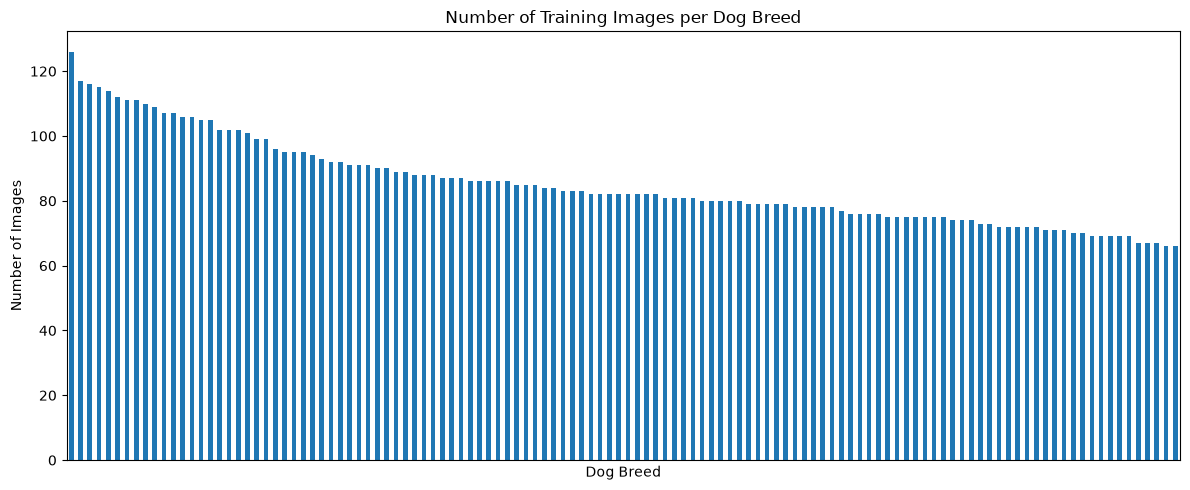

most common breed: scottish_deerhound
number of images for that breed: 126
least common breed: eskimo_dog
number of images for that breed: 66


In [41]:
# counts the number of images for the different breeds and display some info
breed_counts = labels["breed"].value_counts()

plt.figure(figsize=(12, 5))
breed_counts.plot(kind="bar")
plt.title("Number of Training Images per Dog Breed")
plt.xlabel("Dog Breed")
plt.ylabel("Number of Images")
plt.xticks([])
plt.tight_layout()
plt.show()

print("most common breed:", breed_counts.idxmax())
print("number of images for that breed:", breed_counts.max())
print("least common breed:", breed_counts.idxmin())
print("number of images for that breed:", breed_counts.min())

In [42]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

In [43]:
X = []
y = []

for index, row in labels.iterrows():
    image_id = row["id"]
    breed = row["breed"]
    image_path = os.path.join(TRAIN_DIR, image_id + ".jpg")
    image = Image.open(image_path)
    image = image.convert("RGB")
    image = image.resize((32, 32))
    image_array = np.array(image)
    image_array = image_array.flatten()
    X.append(image_array)
    y.append(breed)

X = np.array(X, dtype=np.float32)
y = np.array(y)
X = X / 255.0

print("Number of images:", len(X))
print("Number of features per image:", X.shape[1])
print("Number of breeds:", len(np.unique(y)))
print("Feature matrix shape:", X.shape)

Number of images: 10222
Number of features per image: 3072
Number of breeds: 120
Feature matrix shape: (10222, 3072)


In [44]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Training images:", len(X_train))
print("Validation images:", len(X_val))

Training images: 8177
Validation images: 2045


In [45]:
model = LogisticRegression(max_iter=500, solver="lbfgs")
model.fit(X_train, y_train)
print("Model training complete!")

Model training complete!


In [46]:
y_pred = model.predict(X_val)
accuracy = accuracy_score(y_val, y_pred)
print("Validation accuracy:", accuracy)
print("Validation accuracy percentage:", accuracy * 100)
print("\nClassification report:")
print(classification_report(y_val, y_pred, zero_division=0))

Validation accuracy: 0.037163814180929094
Validation accuracy percentage: 3.7163814180929093

Classification report:
                                precision    recall  f1-score   support

                 affenpinscher       0.06      0.06      0.06        16
                  afghan_hound       0.07      0.09      0.08        23
           african_hunting_dog       0.11      0.12      0.11        17
                      airedale       0.00      0.00      0.00        22
american_staffordshire_terrier       0.17      0.07      0.10        15
                   appenzeller       0.00      0.00      0.00        16
            australian_terrier       0.04      0.05      0.04        21
                       basenji       0.08      0.09      0.09        22
                        basset       0.00      0.00      0.00        16
                        beagle       0.03      0.05      0.04        21
            bedlington_terrier       0.08      0.06      0.06        18
          bernese_

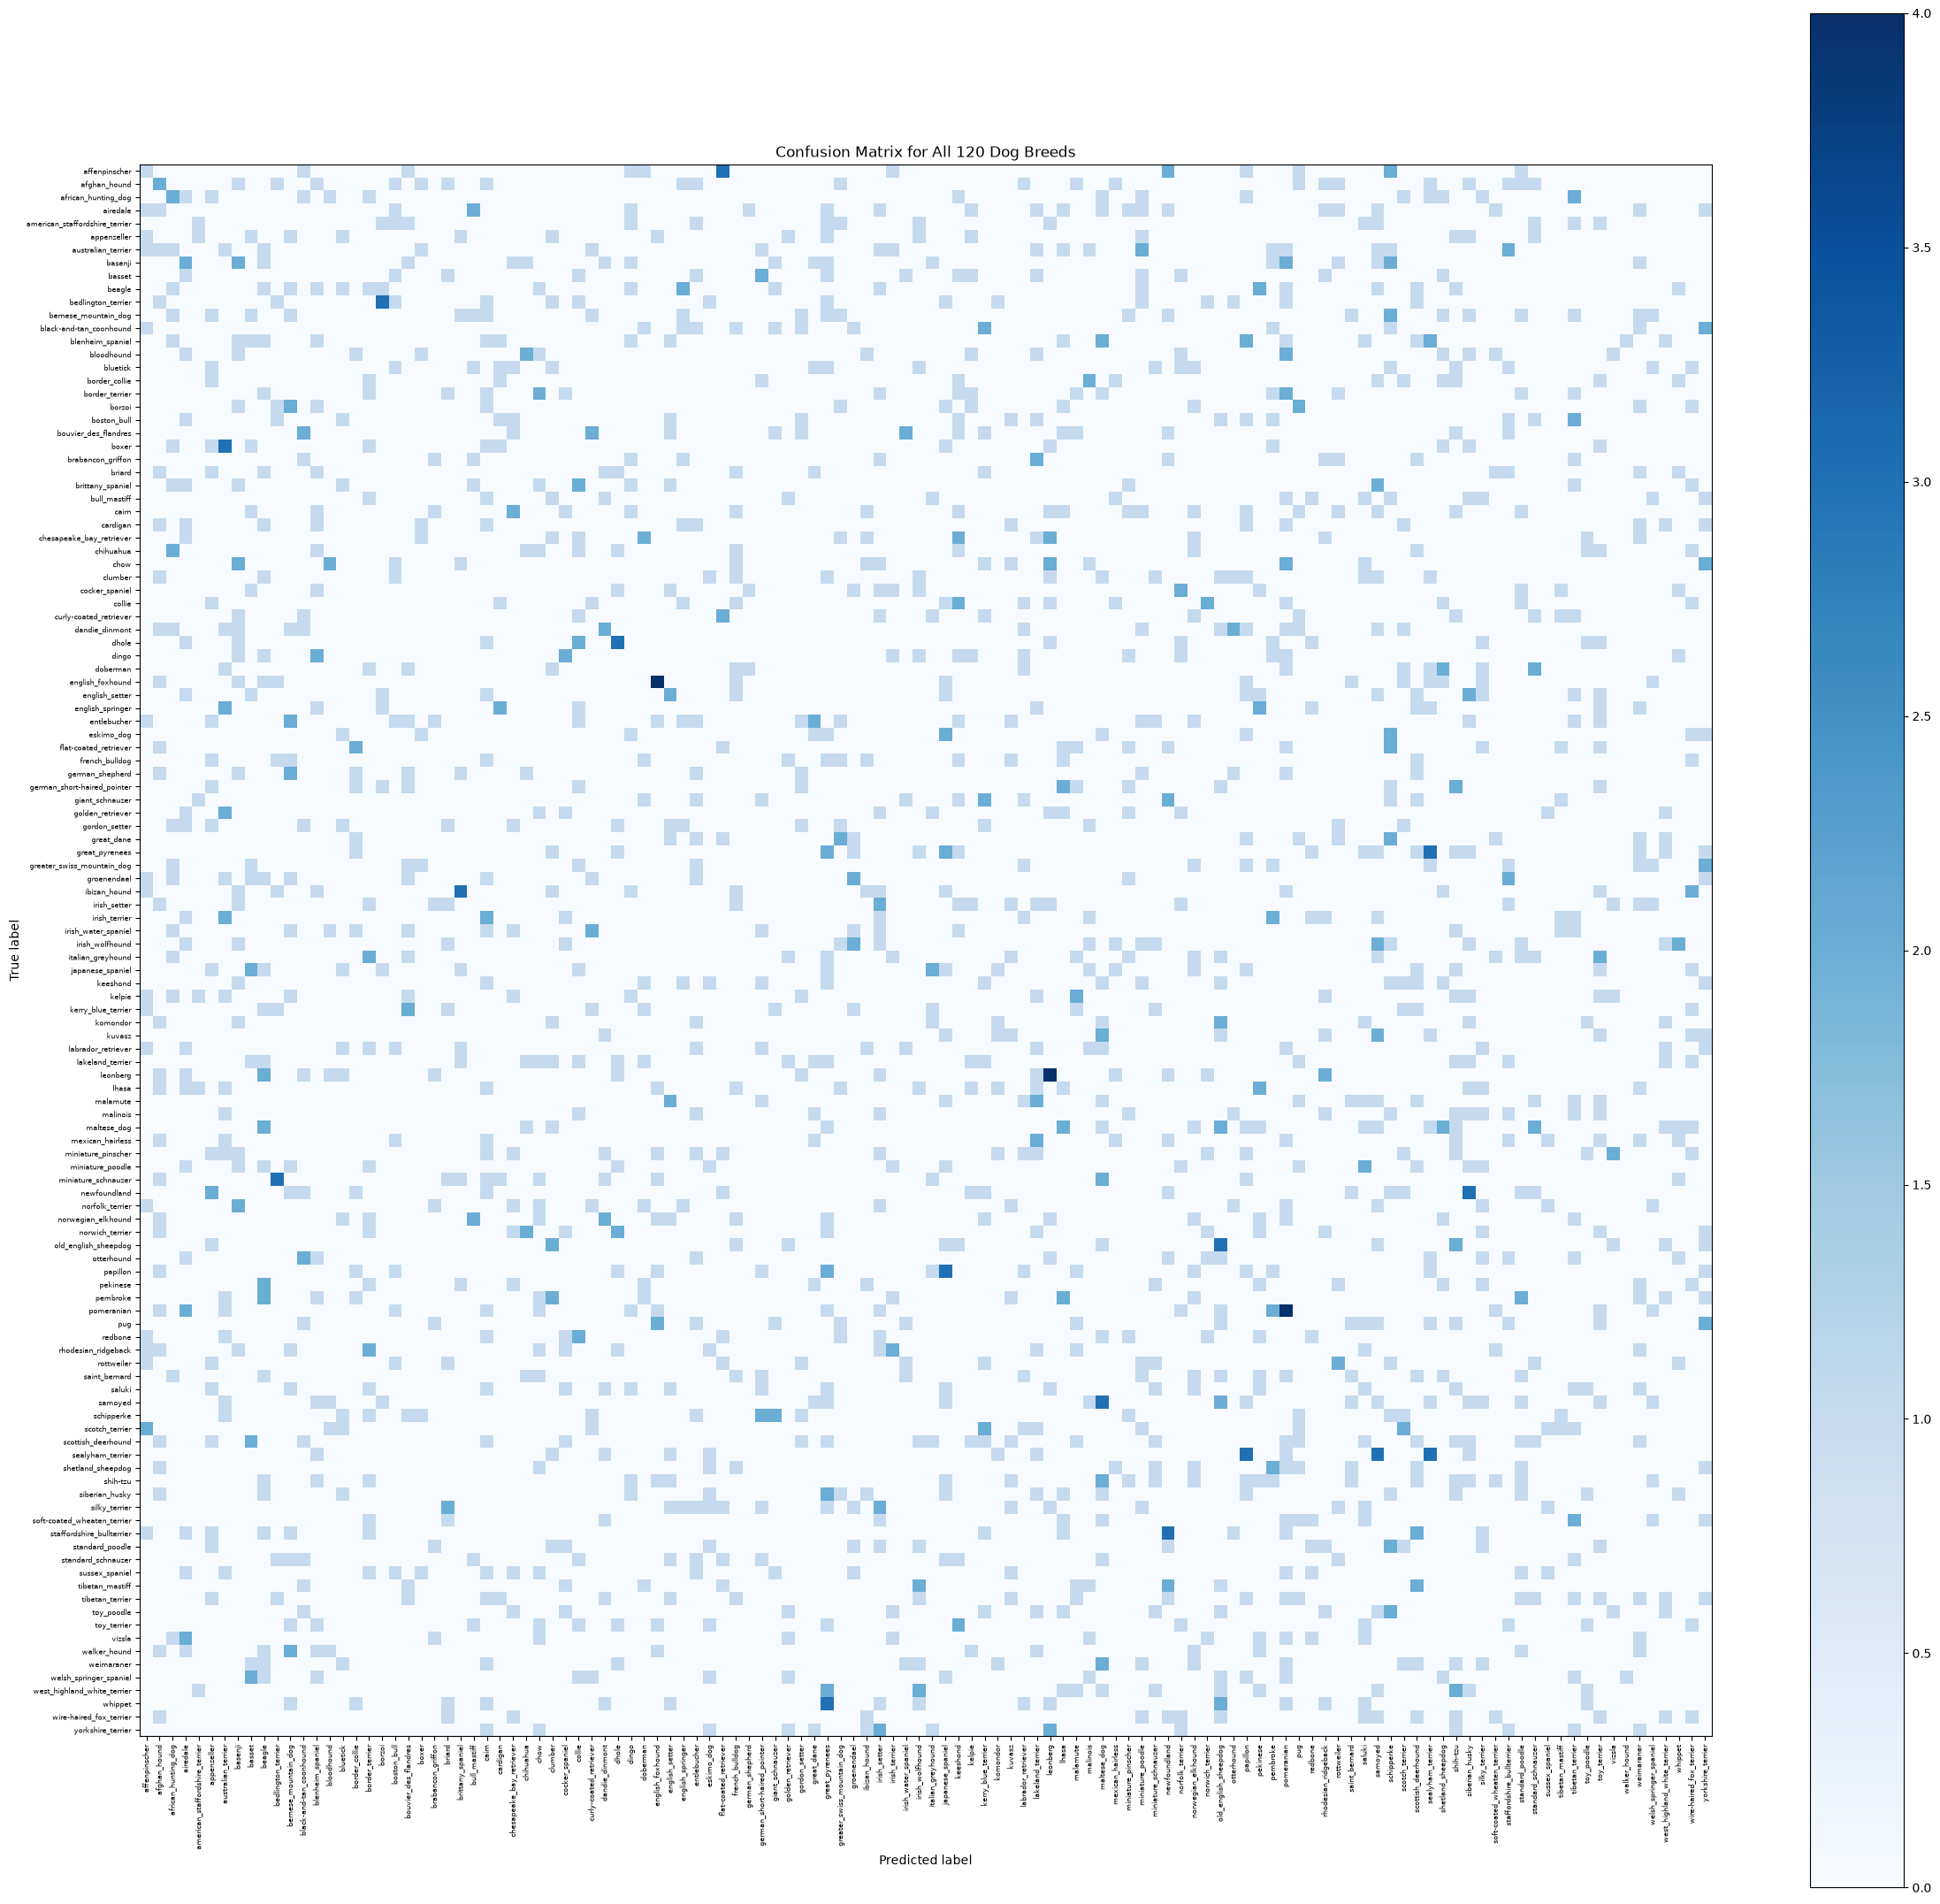

In [47]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Get all dog breed names
breed_names = sorted(np.unique(y_val))

# Create the confusion matrix for all breeds
cm = confusion_matrix(
    y_val,
    y_pred,
    labels=breed_names
)

# Create a large graph
fig, ax = plt.subplots(figsize=(24, 22))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=breed_names
)

display.plot(
    ax=ax,
    include_values=False,
    xticks_rotation="vertical",
    colorbar=True,
    cmap="Blues"
)

# Make breed labels readable
ax.tick_params(axis="x", labelsize=6)
ax.tick_params(axis="y", labelsize=6)
plt.title("Confusion Matrix for All 120 Dog Breeds")
plt.tight_layout()
plt.show()


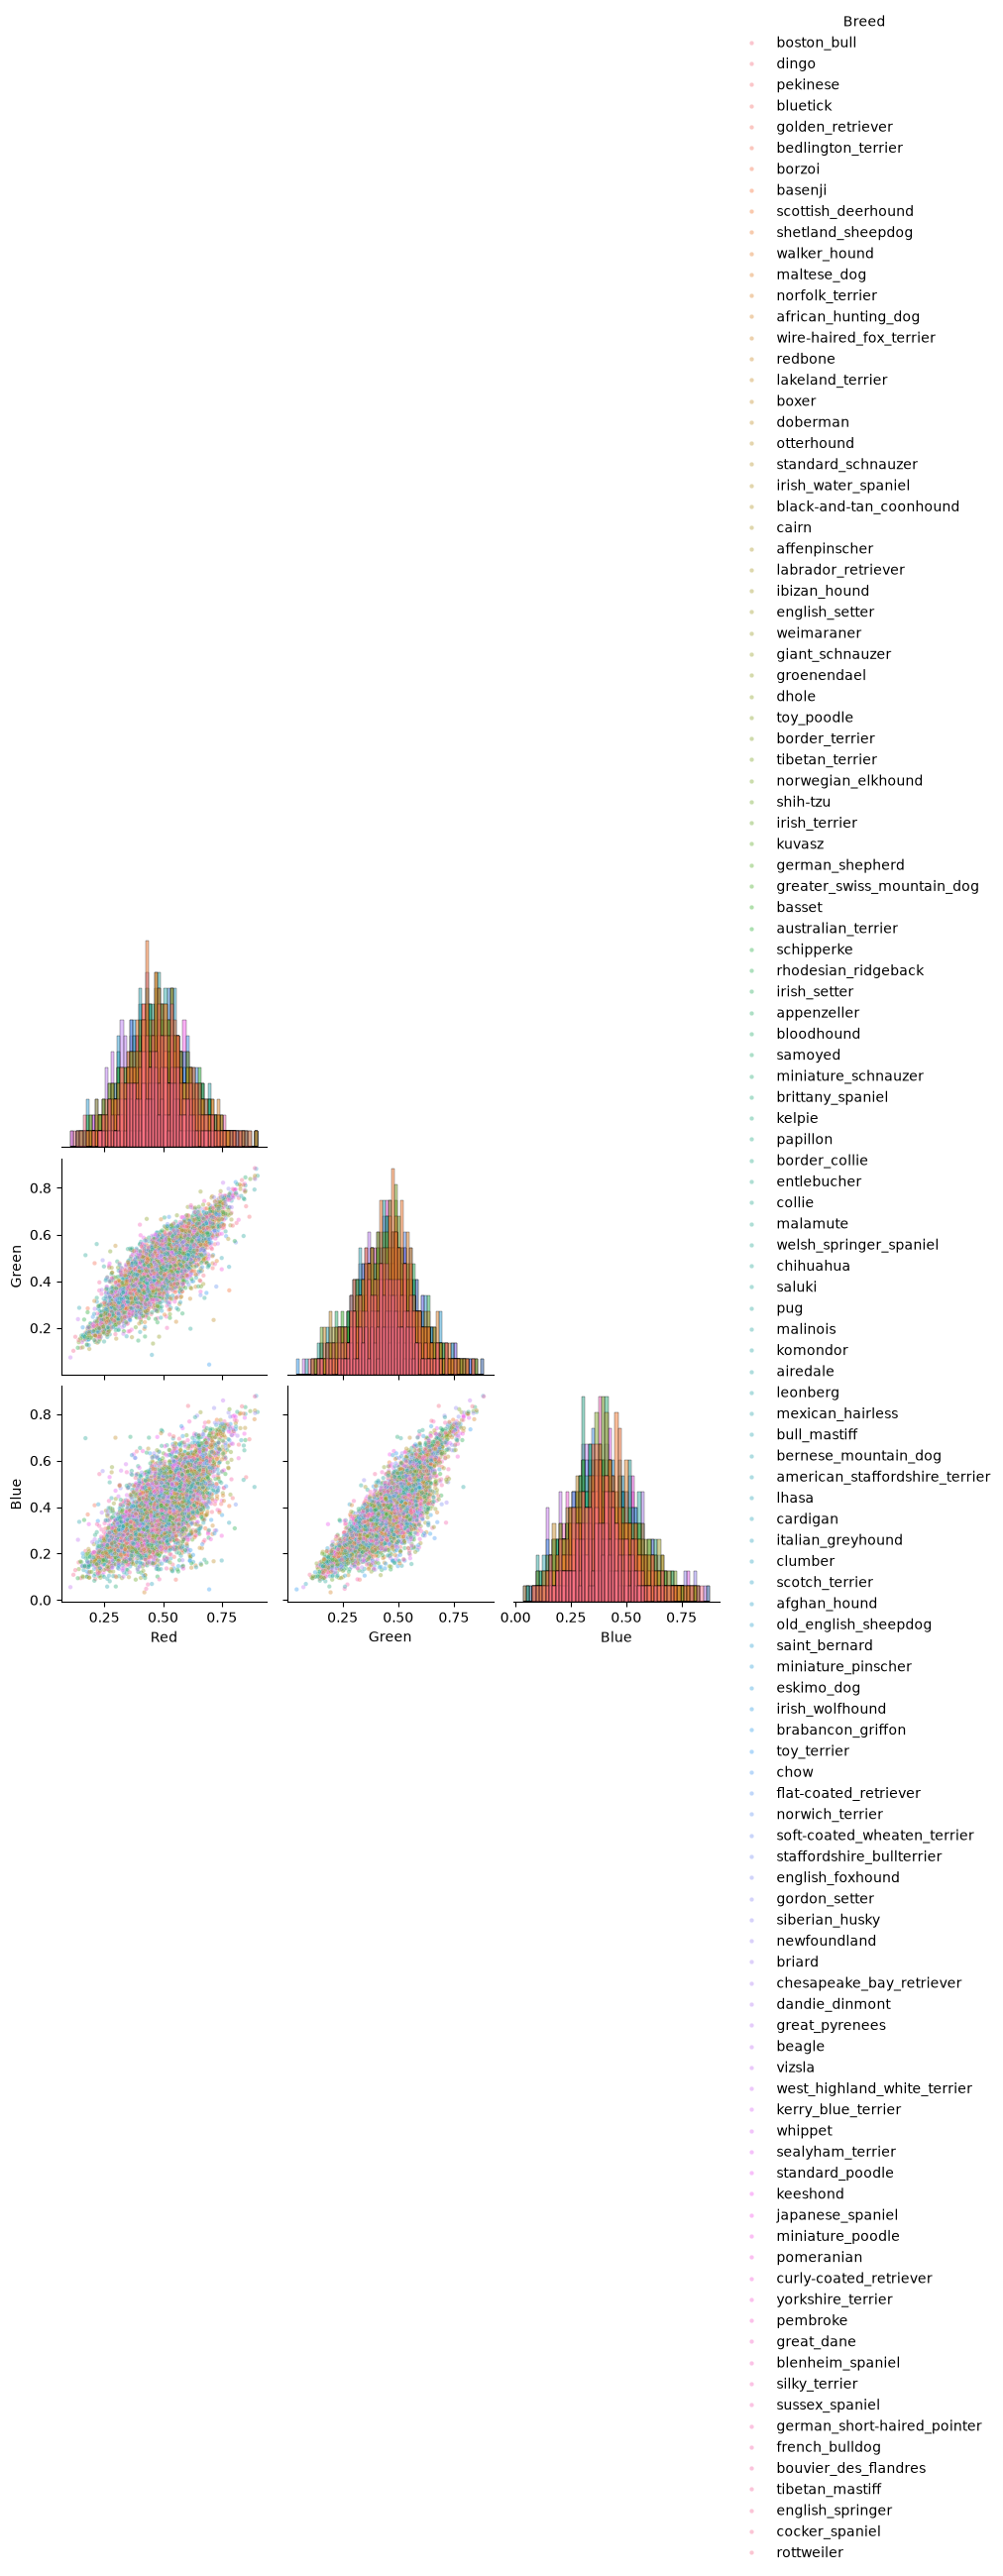

In [48]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Reshape the image data back into 32 x 32 RGB images
images = X.reshape(-1, 32, 32, 3)

# Calculate average color for each image
red = images[:, :, :, 0].mean(axis=(1, 2))
green = images[:, :, :, 1].mean(axis=(1, 2))
blue = images[:, :, :, 2].mean(axis=(1, 2))

# Create a DataFrame with the features and labels
color_data = pd.DataFrame({"Red": red, "Green": green, "Blue": blue, "Breed": y})

# Create the pair plot for all dog breeds
sns.pairplot(color_data, vars=["Red", "Green", "Blue"], hue="Breed", diag_kind="hist", corner=True, plot_kws={"s": 10, "alpha": 0.4})
plt.show()
